# <center>CITS5508 Assignment 2</center>
<center><b>Jason Wang</b></center>
<center><b>24839132</b></center>

In [1]:
# import functions
# importing the functions
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

# to display plots in Jupyter notebook
%matplotlib inline
plt.rcParams['font.size'] = '12'

## Part 1:

### 1. Load the dataset and assign appropriate column names. Briefly describe the dataset:

In [2]:
# importing  in the dataset
# given the dataset has no headers, we've explixitly stated the headers
df = pd.read_csv('processed.cleveland.data',
                header=None,
                names=[
                    'age',
                    'sex',
                    'cp',
                    'trestbps',
                    'chol',
                    'fbs',
                    'restecg',
                    'thalach',
                    'exang',
                    'oldpeak',
                    'slope',
                    'ca',
                    'thal',
                    'num'
                ])
df.head(5)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
# check for missing values in the dataset
(df=='?').sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

The data was loaded and inspected. We can see from the dataset, it does not have any header, so I placed header's for improved readability and for easy processing. We also checked for missing values, since the source documentation where the dataset was taken mentions ca and thal have missing values. Given that there are 4 missing in ca and 2 missing in thal. We will apply preprocessing to the dataset for these variables, since most machine leraning algorithms can't handle missing values.

In [4]:
# check if rows are missing due to randomness or not
missing_rows = df[(df['ca']=='?') | (df['thal']=='?')]
print(missing_rows)

      age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
87   53.0  0.0  3.0     128.0  216.0  0.0      2.0    115.0    0.0      0.0   
166  52.0  1.0  3.0     138.0  223.0  0.0      0.0    169.0    0.0      0.0   
192  43.0  1.0  4.0     132.0  247.0  1.0      2.0    143.0    1.0      0.1   
266  52.0  1.0  4.0     128.0  204.0  1.0      0.0    156.0    1.0      1.0   
287  58.0  1.0  2.0     125.0  220.0  0.0      0.0    144.0    0.0      0.4   
302  38.0  1.0  3.0     138.0  175.0  0.0      0.0    173.0    0.0      0.0   

     slope   ca thal  num  
87     1.0  0.0    ?    0  
166    1.0    ?  3.0    0  
192    2.0    ?  7.0    1  
266    2.0  0.0    ?    2  
287    2.0    ?  7.0    0  
302    1.0    ?  3.0    0  


We can see that the missing values are in random order and that only 6 were missing, this means it's less than 2% of the dataset. Given this, we can drop these instances.

In [5]:
# dropping missing random rows and checking if missing values have been removed
df_cleaned = df.drop(missing_rows.index)
(df_cleaned=='?').sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64

#### (a) How many examples are there? What does each example represent?

In [6]:
# print out the shaped of the dataset before and after cleaning
df = (df, df_cleaned)
for i in df:
    print(i.shape)

(303, 14)
(297, 14)


We can see that the original dataset has over 303 examples. but given that we applied preprocessing to remove the randomly missing rows, there is now only 297 examples. From the source of where the data was taken, Each example represents a patient record capturing certain test measurements to asses a patients risk of heart diseases.

#### (b) How many features are there? Which are numeric and which are categorical?

In [7]:
# check datatypes
df_cleaned.dtypes

age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca           object
thal         object
num           int64
dtype: object

We can see that there are 14 variables in the dataset. The num variable is the target variable, while the remaining 13 are the features. The data types of the features show that for numerical features we have age, sex, cp, trestbps, chol, fbs, restecg, thalach, exang, oldpeak and slope. While, for categorical features we have ca and thal. But, the source of the dataset shows that age, trestbps, chol, thalach, oldpeak and ca are numerical features, while sex, cp, fbs, restecg, exang, slope and thal are categorical. Given this, we will factorized the floats which will signal the machine learning algorithms to treat these features as categorical.

In [8]:
# factorizing the categorical data
categorical = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']
for cat in categorical:
    df_cleaned[cat] = pd.factorize(df_cleaned[cat])[0]

In [9]:
#check data type
df_cleaned.dtypes

age         float64
sex           int64
cp            int64
trestbps    float64
chol        float64
fbs           int64
restecg       int64
thalach     float64
exang         int64
oldpeak     float64
slope         int64
ca           object
thal          int64
num           int64
dtype: object

#### (c) Describe the target attribute (num). The original target indicates the severity of heart disease on an integer scale from 0 to 4. For this assignment, binarise the target: 0 indicates absence of disease, and any value greater than 0 indicates presence.

In [10]:
# count the value distribution for each class
df_cleaned['num'].value_counts()

num
0    160
1     54
2     35
3     35
4     13
Name: count, dtype: int64

The target variable num represents the diagnosis of heart disease, each level representing the severity of the heart disease a patient has. The scale ranges from 0-4, with 0 indicating the absence of heart disease, and 1 to 4 the severity of the disease. Given that we are to binarize the target variable, we binarize it to 0 being no presence of heart disease and 1 being there is a presence of heart disease regardless of the severity.

In [11]:
# binarizing the classes to 0 and 1
df_cleaned['num'] = (df_cleaned['num'] > 0).astype(int)
df_cleaned['num'].value_counts()

num
0    160
1    137
Name: count, dtype: int64

### 2. Split the dataset into a training and testing set. Use 80% of the data for training, and 20% for testing. Make sure to stratify your split.

In [12]:
# import sklearn's train_test_split to employ stratify split
from sklearn.model_selection import train_test_split
# split dataset to X and y labels
X = df_cleaned.drop(columns='num')
y = df_cleaned['num']
# emplot stratify split to get the train and test split for both x and y
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

We used sklearn's train_test_split function to split the data, to apply startify split, stratify hyperparameter is used.

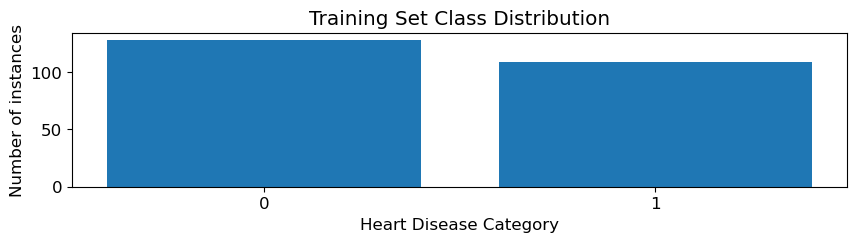

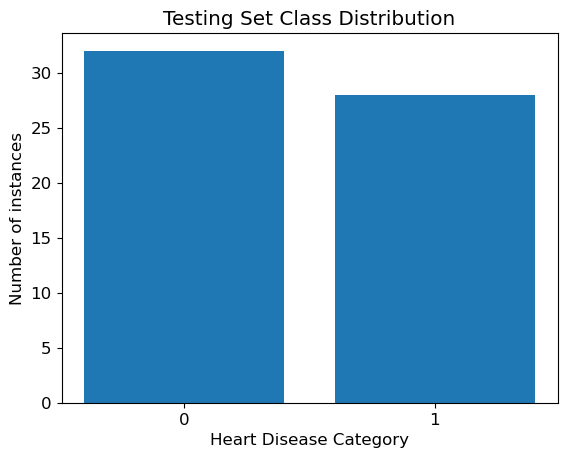

In [13]:
# function to display the distribution of each class
def plot_distribution(y, title):
    classes, counts = np.unique(y, return_counts=True)
    plt.bar(classes, counts)
    plt.xticks(classes)
    plt.xlabel('Heart Disease Category')
    plt.ylabel('Number of instances')
    plt.title(title)
    plt.show()
# display the class distribution for training and test sets
plt.figure(figsize=(10, 2))
plot_distribution(y_train, 'Training Set Class Distribution')
plot_distribution(y_test, 'Testing Set Class Distribution')

We then plot graphs to check if the stratify sampling was applied correctly. It can be seen that both the train and test set for the categories are fairly well distributed. Thus, stratify sampling was applied correctly

### 3. Fit a single Decision Tree classifier using scikit-learn as a baseline and evaluate its performance on the test set.

In [14]:
# import the decision tree classifier from sklearn
from sklearn.tree import DecisionTreeClassifier
# train the basline decision tree classifier using the train set
dtc = DecisionTreeClassifier(random_state=42)
dtc.fit(X_train, y_train)
# visualize the train and test accuracy scores of the train and test set
print(f'train accuracy score: {dtc.score(X_train, y_train)}')
print(f'test accuracy score: {dtc.score(X_test, y_test)}')

train accuracy score: 1.0
test accuracy score: 0.7


We have fitted a decision tree classifier. We have checked the accuracy on both the train set and test set. We can see that the decision tree has achieved a 100% accuracy on the train set, this is expected since decision trees make no assumptions about the data. They will continue to split the training data again and again until they perfectly match the training set, that is it will classify every training point perfectly, even learning noise, thus overfitting the training data and does not generalize well on new unseen data. One fix is to restrict max_depth to regularize the model or to prune the tree, which reduces the risk of over fitting.

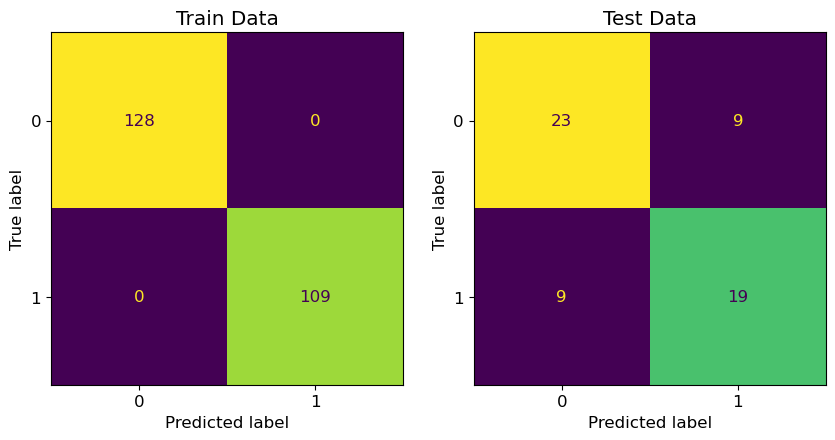

In [15]:
# import the confution matrix functions from sklearn
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# function to display the confusion matrices
def confusion_matrixplots(y, y_pred, title, axis):
    cm = confusion_matrix(y, y_pred)
    display = ConfusionMatrixDisplay(cm)
    display.plot(ax=axis, colorbar=False)
    axis.set_title(title)
# predict the y_label for both train and test to be used to populate the confusion matrix with the actual y labels
y_pred_train_dt = dtc.predict(X_train)
y_pred_test_dt = dtc.predict(X_test)
# show the actual confusion matrix plots
fig, axes = plt.subplots(1, 2, figsize=(10,12))
confusion_matrixplots(y_train, y_pred_train_dt, 'Train Data', axes[0])
confusion_matrixplots(y_test, y_pred_test_dt, 'Test Data', axes[1])

To confirm this is true, we plot the confusion matrix for both the train and test set, this confirms the decision tree is overfitting as it has correclty classified labels correctly in the train data, while is is peforming slightly worse on the test set, leading to worst generalization on unseen data.

### 4. Fit two further ensemble models using scikit-learn:

• A Random Forest classifier with 500 estimators.

In [16]:
# call in sklearn ensemble and import the randomforest classifier and ada boost classifier.
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
# train the random forest classifier with n_estimators = 500, random_state=42 for reproducibility
rfc = RandomForestClassifier(n_estimators = 500, random_state = 42)
rfc.fit(X_train, y_train)

RandomForestClassifier(n_estimators=500, random_state=42)

• An AdaBoost classifier with 500 estimators.

In [17]:
# train the ada boost classifier with n_estimators = 500, random_state=42 for reproducibility
abc = AdaBoostClassifier(n_estimators = 500, random_state = 42)
abc.fit(X_train, y_train)

AdaBoostClassifier(n_estimators=500, random_state=42)

### 5. Combine your models from the previous steps in a soft-voting Voting Classifier.

To utilize the soft-voting Vosting Classifier, we first import the ensemble method from sklearn and specify the hyperparameter 'voting' as soft. Since, by default the voting classifier assumes hard voting.

In [18]:
# import voting classifier
from sklearn.ensemble import VotingClassifier
# train and fit the voting classifier with the estimators trained previously
voting_clf = VotingClassifier(
    estimators = [
        ('dtc', dtc),
        ('rfc', rfc),
        ('abc', abc)
    ],
    voting = 'soft'
)
voting_clf.fit(X_train, y_train)

VotingClassifier(estimators=[('dtc', DecisionTreeClassifier(random_state=42)),
                             ('rfc',
                              RandomForestClassifier(n_estimators=500,
                                                     random_state=42)),
                             ('abc',
                              AdaBoostClassifier(n_estimators=500,
                                                 random_state=42))],
                 voting='soft')

### 6. Compare the performance of all four models (the decision tree baseline, the Random Forest, the AdaBoost classifier, and the voting classifier) on the test set:

#### (a) Create a table of precision, recall, and F1-scores for each model.

In [19]:
# import precision, recall and f1 scores to evaluate performances
from sklearn.metrics import precision_score, recall_score, f1_score
# dictionary to store each metric for each algorithm
y_train_pred = {}
y_test_pred = {}
results = {}
# function to get the performance metrics for each estimator and storing them into the dictionaries
for name, clf in voting_clf.named_estimators_.items():
    y_pred = clf.predict(X_test)
    results[name] = {
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred)
    }
    y_test_pred[name] = y_pred
    y_pred = clf.predict(X_train)
    y_train_pred[name] = y_pred
# the voting classifier performance metrics stored into the dictionaries
y_pred_voting = voting_clf.predict(X_test)
results['voting'] = {
    'Precision': precision_score(y_test, y_pred_voting),
    'Recall': recall_score(y_test, y_pred_voting),
    'F1-Score': f1_score(y_test, y_pred_voting)
}
y_test_pred['voting'] = y_pred_voting
y_pred_voting = voting_clf.predict(X_train)
y_train_pred['voting'] = y_pred_voting

In [20]:
# printing the results for each algorithm and their respective metric results
results_df = pd.DataFrame(results).T.round(4)
print(results_df)

        Precision  Recall  F1-Score
dtc        0.6786  0.6786    0.6786
rfc        0.8519  0.8214    0.8364
abc        0.7857  0.7857    0.7857
voting     0.6786  0.6786    0.6786


From the metric results, we can see that the random forest classifier performs the best out of all the classifiers, followed by the adaboost classifier and decision tree performs the worst. Surprisingly, the voting classifier has a similarly low result as with the decision tree. This maybe due to the decision tree's overfitting behaviour and highly confident predictions influencing the soft voting classifier, which we will further discuss later.

#### (b) Display a confusion matrix for each model.

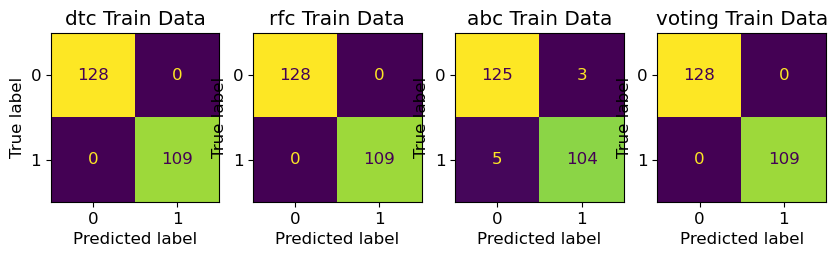

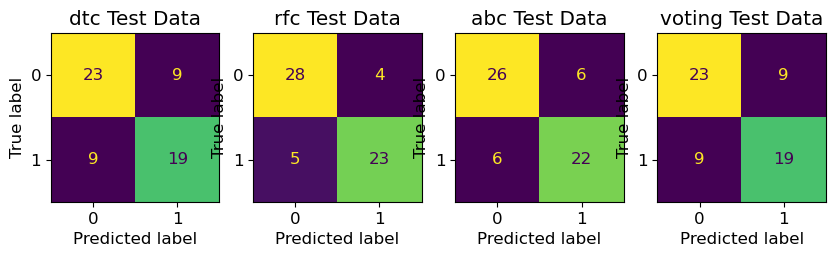

In [21]:
# plotting the confusion matrices for each model and for both the train and test set
fig, axes = plt.subplots(1, 4, figsize=(10,12))
for i, (name, y_pred) in enumerate(y_train_pred.items()):
    confusion_matrixplots(y_train, y_pred, f'{name} Train Data', axes[i])

fig, axes = plt.subplots(1, 4, figsize=(10,12))
for i, (name, y_pred) in enumerate(y_test_pred.items()):
    confusion_matrixplots(y_test, y_pred, f'{name} Test Data', axes[i])

The confusion matrixes reinforces this finding. The random forest classifier perfroms the best, having the highest and very balanced predictions on the train and test sets, followed by the ada boost classifier, while the decision tree classifier and the voting classifier are both performing the same, having 100% accuracy in the train set, but fairly poor performance on the test set, which shows they are overfitting. Overall, this reinforces that the decision tree's overfitting behaviour and highly confident predictions drives the voting of the soft voting classifier. This will also be further discussed in the later section.

### 7. Plot the feature importances of your Random Forest. Briefly comment on which features contribute most strongly to predictions, and whether this matches what you would expect.

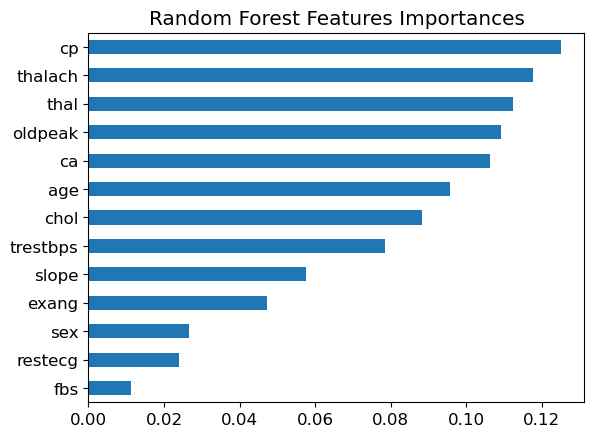

In [22]:
# training and fitting the random forest classifier and to get the feature importances(sorted)
rfc.fit(X_train, y_train)
feature_importances = pd.Series(rfc.feature_importances_, index=X_train.columns)
feature_importances = feature_importances.sort_values(ascending=True)
# plot the graph of the feature importances from the random forest classifier
feature_importances.plot(kind='barh')
plt.title('Random Forest Features Importances')
plt.show()

One feature of random forests is it can measure the relative importance of each features, the relative importance is based on the average total decrease in the Gini Index. Thus, a larger value indicates an important feature. For this cp, thalach, and thal are the top 3 indicators of heart diseases, this is expected since these are well established predictors in the medical field that can identify signs of heart diseases. The feature importance capability is useful if we need to perform feature selection.

### 8. Comment on your results in detail. Investigate the following ideas:

#### (a) How do the models compare to each other? Which model performs best? Is this what you expected?

Based on the results, we see that random forest performed the best (precision: 0.8519, recall: 0.8214, f1: 0.8364), followed by the ada boosting classifier (precision: 0.7857, recall: 0.7857, f1: 0.7857), ten lastly both the soft voting classifier and decision tree performed the worst with the same performance values(precision: 0.6786, recall: 0.6786, f1: 0.6786). The random forest's performance was better than the decision tree, this was expected since a random forest classifier is more convinient and more optimized for decision trees that also applies bagging ensemble method. This means the random forest classifier trades higher bias for a lower variance, yeilding better overall results. The ada boosting classifier's performance was also expected since it trains by iteratively focus on misclassified samples, which reduces bias. Moreover, the voting classifier exectedly performed the same with the decision tree classifier, which performed the worst, this is most likely due to the soft voting classifier works by averaging the predicted probabilities of all the classifiers and taking the class with the highest average probability, since the decision tree was not regularized, it make no assumptions about the data and continues splitting till it perfectly fits the data and overfitting. This results in the decision tree predictions to have overconfident probability outputs of 1 or 0, thus dominating the averaging process and making the voting classifier to perform badly.

#### (b) Bagging and boosting reduce different sources of error. Which type of ensemble works better here, and why might that be?

Bagging and boosting are very different ensemble techniques. Bagging trains multiple based learners independently on different random subset of the training set, these subsets are randomly sampled with replacement, then it aggregates their predictions by averaging. This trades higher bias for lower variance, thus generalizing better. Boosting on the other hand combines several weak learners into a strong learner, it trains predictors sequentially, with each trying to correct its predecessor, which reduces bias. Based on the performance results, we can see that bagging performs better compared to boosting. This is because a random forest classifier applies bagging method, while ada boost applies a boosting method. We see that bagging has higher performance and better generalization based on the confusion matrix compared to boosting. This suggests that the primary error source in the dataset is variance and not bias. This is evident in the decision tree, where it performs perfectly on the training data, but generalizes poorly on new unseen data, showing overfitting. Since bagging lowers variance, this explains why it is a better ensemble method for this particular dataset.

#### (c) What are the advantages and disadvantages of using an ensemble method over the decision tree baseline?

Ensemble methods offer a few advantages over a baseline decision tree. We can see that if left unchecked, a decision tree is prone to over fitting, as evidenced by the train and test accuracy scores and confusion matrix. Ensemble methods a can address this, by combining multiple base learners, where bagging reduces the variance by training on different subsets of the train data with replacement and average their predictions and boosting helps reduces bias by sequentially correcting misclassified classes. These methods lead to over all generalization on unseen data, as seen with the performance metrics with the random forest and ada boost, both out performing the decision tree classifier. Moreover, ensemble methods are more robust to noise and outliers since no single learner dominates the predictions.

However, ensemble methods do not always guarantee better performance over a single decision tree. As shown by the voting classifier, which performs similarly to the decision tree classifier, poorly configured base learners within an ensemble method can drag down the over all performance. This is due to the decision tree's lack of regularization, which causes it to overfit, thus, dominating the sift voting process. Another disadvantage is that ensemble methods are black box models, where the final predictions make it difficult to interpret. Also, ensemble methods are more computationally expensive, as training the estimators requires considerably more time and memory compared to a single decision tree classifier. Lastly, ensemble methods are more complex, since it introduces more hyperparameters to tune (learning rate, n_estimators and max features), compared to a decision tree, which has fewer and more straightforward hyperparameters.

## Part 2

### 1. Load the Olivetti Faces dataset using the code above. Briefly describe the dataset:

In [23]:
# importing the face dataset from sklearn
from sklearn.datasets import fetch_olivetti_faces
data, targets = fetch_olivetti_faces(return_X_y=True)

In [24]:
# printing the shape of the dataset and the unique classes from the target variable
print(data.shape)
print(len(np.unique(targets)))

(400, 4096)
40


#### (a) How many examples are there? What does each example represent?

There are 400 examples in the dataset, each example represent a greyscale photograph of a human face, taken against at a dark barkground with the person facing forward. The photos of the person vary by lighting, facial expressions and facial details. These images were collected from 40 individuals at AT&T Laboratories Cambridge between 1992 and 1994. In short, each example represents an image from 40 people with different expressions and details.

#### (b) Describe the features. How many features are there, and what does each feature represent?

In [25]:
# checking the values in the data
print(data.min(), data.max())

0.0 1.0


There are around 4096 features, each feature represents a the intensity of a pixel from a grey scaled image, with values ranging from 0(white) to 1(black), values in between represent a different shade of grey. Together these 4096 features should show an image of a person in greyscale. The source of the dataset states each images had a 64*64 pixel resolution, which was then flattened into a single row of 4096 features.

### 2. Sample a random example from each class and display the images in a grid. Ensure each image is labelled with its class.

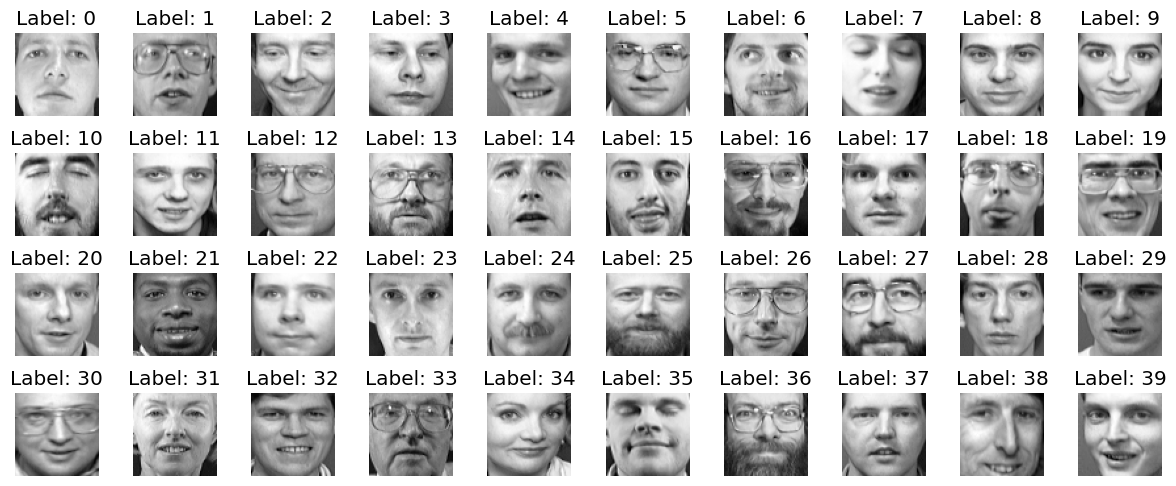

In [26]:
# random seed for reproducibility
np.random.seed(42)
fig, axes = plt.subplots(4, 10, figsize=(12, 5))
# plotting the selected images
for i, ax in enumerate(axes.flat):
    class_i = np.where(targets == i)[0]
    idx = np.random.choice(class_i)
    image = data[idx].reshape(64,64) # reshaping the flat vector into a 64*64 image
    label = targets[idx] # the corresponding label
    ax.imshow(image, cmap='gray')
    ax.set_title(f"Label: {label}")
    ax.axis('off')
# showing the images
plt.tight_layout()
plt.show()

The images and target label reinforces the description of the dataset, where the features are the pixels representing the greyscale pixel values of a person's image and the label is just unique identifier of each individual.

### 3. Fit Principal Component Analysis (PCA) on the full dataset using scikit-learn.

In [27]:
# importing PCA from sklearn and fitting the data
from sklearn.decomposition import PCA
pca = PCA()
pca.fit(data)

PCA()

#### (a) Plot the cumulative explained variance ratio against the number of components. Choose a number of components that retains at least 95% of the variance and report this number.

In [28]:
# getting the cumulative sum of the variances for each component
cumsum = np.cumsum(pca.explained_variance_ratio_)
# getting the maximum components that equate to 95% variance, adding 1 since python starts at index 0
d = np.argmax(cumsum >= 0.95) + 1
# print out results
print(f'The number of components to maintain at least 95% varaince: {d}')

The number of components to maintain at least 95% varaince: 123


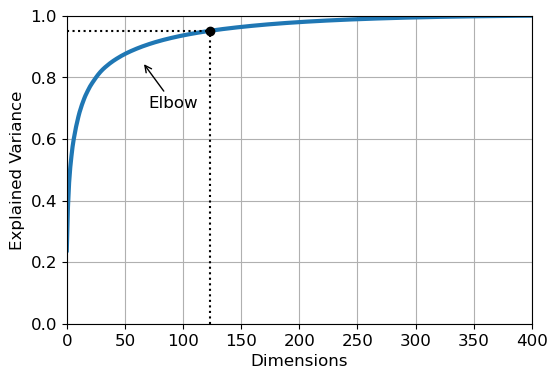

In [29]:
# code to plot the cumulative explained variance ratio against the number of components
plt.figure(figsize=(6,4))
plt.plot(cumsum, linewidth=3)
plt.axis([0,400,0.0,1.0])
plt.xlabel('Dimensions')
plt.ylabel('Explained Variance')
plt.plot([d,d],[0, 0.95], "k:")
plt.plot([0,d],[0.95, 0.95], "k:")
plt.plot(d, 0.95, "ko")
plt.annotate("Elbow", xy=(65, 0.85), xytext=(70, 0.7), arrowprops=dict(arrowstyle="->"))
plt.grid(True)
plt.show()

Principal component analysis is a dimensionality reduction technique, it finds an orthogonal set of directions(principal component) that maximizes the variance of the projected data.. In the context of the dataset, the cumulative explained variance plot shows how much total variance is retained as more principal components are added. We observe that 123 components is the optimal number of components that retain 95% of the total variance in the dataset. This means the original 4096 features can be represented in a much lower 123 feature space while still preserving most of its important structure.

#### (b) Display the first 10 principal components as 64 × 64 images. These are known as eigenfaces. Explain what these components represent and how they relate to the original images.


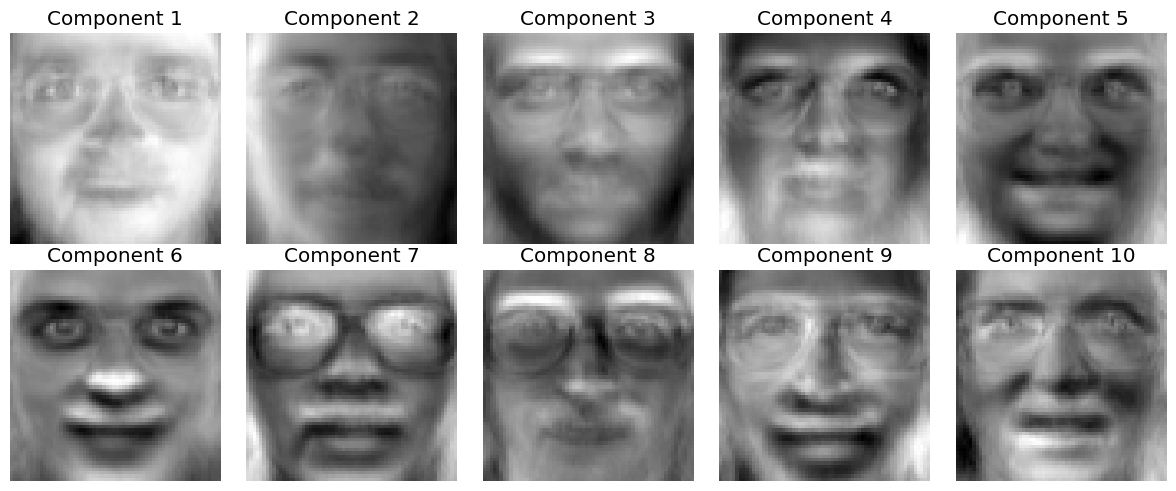

In [30]:
# getting the first 10 principal components
eigenfaces = pca.components_[:10].reshape((10, 64, 64))
# plotting the selected eigenfaces
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(eigenfaces[i], cmap='gray')
    ax.set_title(f'Component {i+1}')
    ax.axis('off')
# showing the eigen faces
plt.tight_layout()
plt.show()

The first 10 eigenfaces above represents the first 10 principal components reshaped into images. Each eigenface is a principal component, meaning it represents a direction in high dimensional image space where the data varies the most. Whe reshaped back into 64*64 images, these components reveal patterns of variation across all faces in the dataset. Each original face image can be represented as a linear combination of these eigenfaces, where each coefficient determines how strongly it contributes to the reconstruction of the image. The first few components capture the most significant global variation, while later components capture more finer details and noise. Any face in the dataset can be approximated as a weighted combination of these eigenfaces.

#### (c) Project the data onto the first two principal components and produce a scatter plot, colouring each point by its class. Comment on whether 2 components are sufficient to separate the classes.

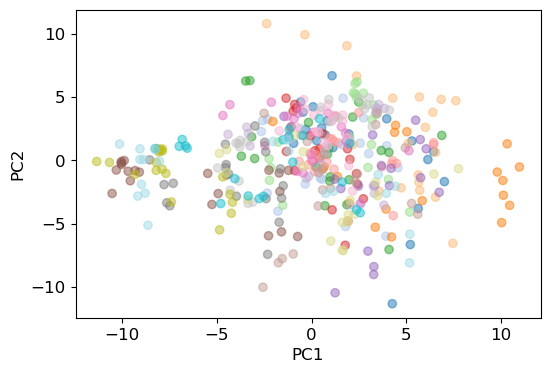

In [31]:
# getting the first 2 principal components
pca2 = PCA(n_components=2)
project_data = pca2.fit_transform(data)
# plotting the scatterplot of the first 2 principal components
plt.figure(figsize=(6,4))
plot = plt.scatter(project_data[:,0], project_data[:,1], c=targets, cmap='tab20', alpha=0.5)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

We can see that projecting the first 2 principal components into a scatterplot does not yield any sufficient results, meaning 2 components are not sufficient to seperate the classes. This can be seen in the scatter plot where there is significant overlap between the different classes, which shows no distinct clusters visible. TThis is because PCA maximizes variance rather than class separability, the first 2 captures the most dominant global variations which are shared across all individual faces rather than distinctive features, therefore not distinct enough to seperate each individual. Also, as stated earlier, 123 components are needed to retain at least 95% of the variance, meaning the remaining 121 components contribute additional details and patterns that are crucial for distinguishing between classes.

#### 4. Apply k-Means clustering to the original feature space. Use k equal to the number of classes.

In [32]:
# importing KMeans and silhouette_score
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
# training the KMeans on the full data and getting the number of clusters
kmeans = KMeans(n_clusters=40,random_state=42)
clusters = kmeans.fit_predict(data)

#### (a) Report the silhouette score of the clustering.

In [33]:
# getting the silhouette score of the clusters from the full/original data and printing it out
s_score = silhouette_score(data, clusters)
print(f'The Silhouette Score is {s_score}')

The Silhouette Score is 0.12942750751972198


The silhouette score of 0.1294 indicates that the k-means clustering on the original feature space is relatively poor, this suggests that the clusters are overlapping and not well seperated. 

#### (b) Visualise the cluster centroids as 64 × 64 images. Compare them to the eigenfaces from the previous task.

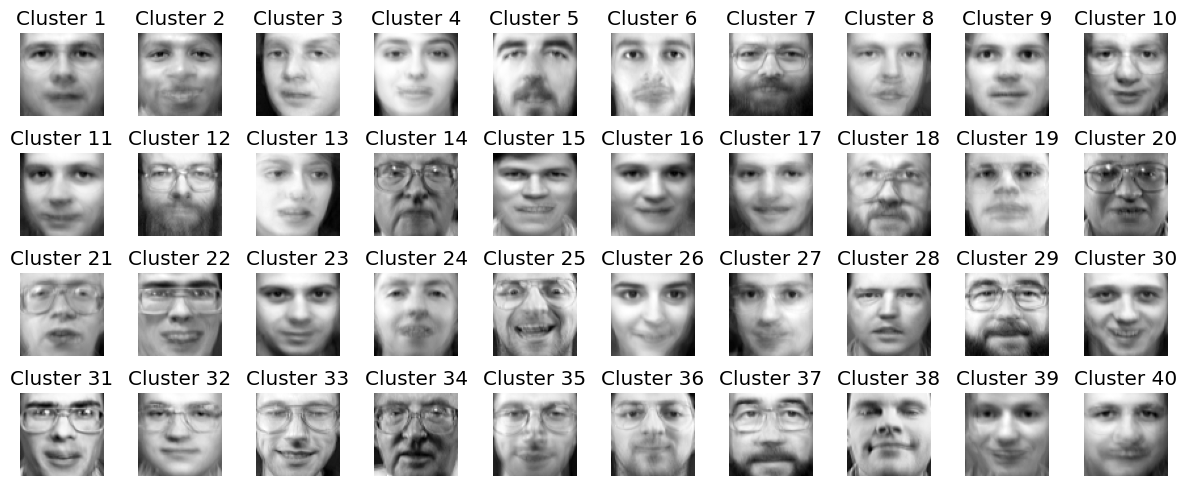

In [34]:
# getting the centroids of each cluster and reshaping them into images
centroids = kmeans.cluster_centers_.reshape((40, 64, 64))
fig, axes = plt.subplots(4, 10, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(centroids[i], cmap='gray')
    ax.set_title(f'Cluster {i+1}')
    ax.axis('off')
# displaying images
plt.tight_layout()
plt.show()

Reshaping the clustered centroids into 64*64 images reveals average faces of each cluster. Unlike eigenfaces which captures the directions of maximum variance and appearing somewhat abstract in pattern, the clustered centroids resemble more recognisable and more realistic faces since these centroids represent the mean pixel values of all faces assigned to that cluster. However, both the eigenfaces and the cluster centroids share similarities when capturing global facial structures suchs as lighting and overall face shape. The main difference is that eigenfaces are used as basis vectors where any face can be reconstructed based on a combination of eigenfaces, while cluster centroids act more as the average face of each cluster, where each face in the dataset is assigned to its nearest centroid.

### 5. Repeat the k-Means clustering, this time on the PCA-reduced data.

In [35]:
# getting the 123 principal components and transforming the data to only inclue the 123 principal components
pca_3 = PCA(n_components = d)
reduced_data = pca_3.fit_transform(data)
# reapplying kmeans on PCA reduced data
kmeans_2 = KMeans(n_clusters=40,random_state=42)
clusters_2 = kmeans_2.fit_predict(reduced_data)

#### (a) Report the silhouette score for the PCA-reduced clustering.


In [36]:
# getting and printing out the silhouette score of the PCA reduced data
s_score_2 = silhouette_score(reduced_data, clusters_2)
print(f'The Silhouette Score is {s_score_2}')

The Silhouette Score is 0.15645131468772888


The silhouette score (0.1565) of the PCA-reduced clustering is slightly higher than the full feature space silhouette score, this suggests that PCA improves the quality of k-means clustering. This is likely due to PCA removing the noise and redundant information from the original 4096 features and that the 123 components captures 95% of the variance, thus making the clusters more compact and better seperated in the reduced feature space.

#### (b) Plot the silhouette diagrams for both the original and PCA-reduced clusterings, and compare them.

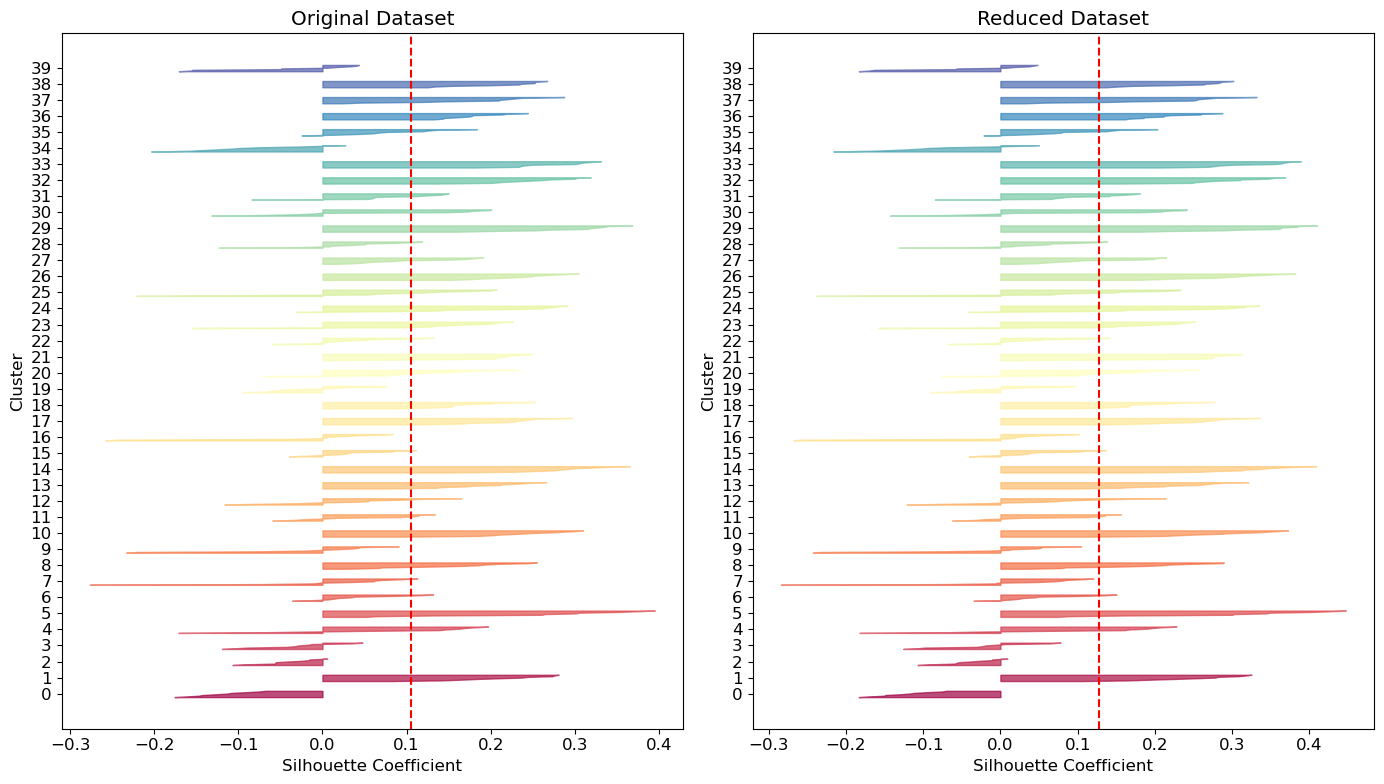

In [37]:
# import silhouette samples and fixed functions to help plot and display the silhouette diagrams
from sklearn.metrics import silhouette_samples
from matplotlib.ticker import FixedLocator, FixedFormatter
# define a function to display the silhouette diagram
def sil_plot(ax, X, y, title):
    n_clusters = len(np.unique(y))
    sil_val = silhouette_samples(X, y)
    avg_score = silhouette_score(X, y)

    padding = len(X)//30
    pos = padding
    ticks = []

    for i in range(n_clusters):
        coeffs = sil_val[y == i]
        coeffs.sort()

        color = plt.cm.Spectral(i/n_clusters)
        ax.fill_betweenx(np.arange(pos, pos+len(coeffs)), 0, coeffs, facecolor=color, edgecolor=color, alpha=0.7)
        ticks.append(pos + len(coeffs)//2)
        pos += len(coeffs)+padding

    ax.yaxis.set_major_locator(FixedLocator(ticks))
    ax.yaxis.set_major_formatter(FixedFormatter(range(n_clusters)))
    ax.axvline(x=avg_score, color='red', linestyle='--')
    ax.set_title(title)
    ax.set_xlabel('Silhouette Coefficient')
    ax.set_ylabel('Cluster')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 8))

sil_plot(ax1, data, targets, 'Original Dataset')
sil_plot(ax2, reduced_data, targets, 'Reduced Dataset')
# plotting the diagrams
plt.tight_layout()
plt.show()

The silhouette diagrams for both the original and PCA-reduced clustering appear very similar, which is expected since the 123 PCA components retained 95% of the variance from the original 4096 features. This suggests the majority of the information and cluster structure is well preserved in the PCA-reduced feature space, which results in a very similar silhouette diagram as the original. The only noticeable difference is the mean score (dashed line) sitting slightly further right in the reduced PCA feature space compared to the mean score of the original feature space, which is consistent with the silhouette scores. Both diagrams still show some negative silhouette coefficients, suggesting that even with PCA, some clusters are still overlapping. This is expected since facial features share similar traits that make if difficult for k-means to perfectly separate clusters regardless of dimensionality reduction.

### 6. Comment on your results in detail. Investigate the following ideas:

#### (a) How does PCA affect the quality of the k-Means clustering? Discuss the performance.

It seems that applying PCA before k-means clustering improved the clustering quality, as evidenced by the higher silhouette score on the k-means clustering on the PCA-reduced dataset compared to the original feature space (0.1565 vs 0.1294). This improvement maybe due to the original feature space consisting of 4096 features, which is suffering from the curse of dimensionality, where in high dimensional spaces, distances between points become less meaningful and less discriminative making it difficult for kmeans for find well-separated clusters since k-Means relies on distance emtrics to assign points to their nearest centroid. So by reducing the dimensionality to 123 components, PCA makes the distances more meaningful and descriminative, which allows k-means to form more distinct clusters. Another reason for the improvement is likely due to PCA removing noise and redundant data from the original feature space, since it retains 123 of the principal components that capture 95% of the variance, which k-means operated on this reduced and cleaner dataset, resulting in to better cluster separation. However, there are some clustering with negative silhouette values indicating that even with PCA applied the clusters are still overlapping. Mostly cause PCA maximises variance rather than class seperability, so the reduced feature space is not that optimal for perfectly seperated clusters.

#### (b) What are the advantages and disadvantages of using PCA before clustering, compared with clustering on the raw features?

The advantages of applygin PCA before clustering is that is solves the curse of dimensionality by reducing the feature space from 4096 features to 123 features. This makes distances between the points moremeaningful and allowing k-means to separate clusters better as evidenced by the higher silhouette score. Another, PCA removes noise and redundant information, which allows k-means to focus more on the most important direction of variation captured by the principal components. PCA also reduces the computational cost of k-means since it captured 123 feateres that capture 95% of the variance, which resulted in k-means to perform better when using the PCA reduced features compared to using the origina 4096 features.

However, a disadvantage for applying PCA before clustering is that PCA introduces a loss compression, the remaining 5% of variance that was not considered may contain some distinct features that could help distinguish between individuals, potentially losing important clustering information. Also, principal components are linear combinations of the original pixel values, making them less interpretable than the original features, while eigenfaces can be visualised as abstract facial patterns, it is difficult to understand what each principal component physically represents in terms of specific facial features. Finally, PCA assumes that the directions of the maximum variance are the most informative for clustering, but does not necessarily mean the most discriminative features for separating individuals, which may not follow the directions of the maximum variance captured by PCA.